# Reconnaissance des formes avancée :
# TP Fuzzy C-means :

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from google.colab import drive

# Montage du Google Drive pour accéder au dossier DataFuzzy (on y a stocké les images milky-way-nvg.png et milky-way.png)
drive.mount('/content/drive')

Mounted at /content/drive


## Focntions principales de l'algo Fuzzy C-means :

In [ ]:

def init_mat_appartenance(n_pixels, n_clusters) :
    """
    Cette fonction initialise aléatoirement la matrice des degrés d'appartenance U.

    Paramètres :
        n_pixels (int)   : Nombre total de points/pixels (N).
        n_clusters (int) : Nombre de classes (C).

    Retour :
        ndarray : (n_pixels, n_clusters) - Matrice U_0 normalisée (la somme de chaque ligne vaut 1).
    """

    U_0 = np.random.rand(n_pixels, n_clusters)

    # keepdims=True préserve la dimension 2D (n_pixels, 1)
    # pour autoriser la division (broadcasting) sur chaque colonne de U_0
    U_0 = U_0 / U_0.sum(axis=1, keepdims=True)

    return U_0

def calcul_centroides(data, U, m) :
    """
    Cette fonction met à jour la position des centroïdes en fonction des degrés d'appartenance.

    Paramètres :
        data (ndarray) : Les données d'origine.
        U (ndarray)    : Matrice d'appartenance actuelle.
        m (float)      : Paramètre de flou (m > 1).

    Retour :
        ndarray : Les nouveaux centroïdes mis à jour.
    """

    # Création d'une nouvelle matrice pour préserver U
    U_m = np.power(U, m)

    # Transposition de U_m pour permettre le produit matriciel
    clusters_num = np.dot(U_m.T, data)
    clusters_den = U_m.sum(axis=0)

    # Si data est en 2D, on ajuste pour la division
    if data.ndim > 1:
        clusters_den = clusters_den[:, np.newaxis]

    return clusters_num/clusters_den

def calcul_distances(data, centroides) :
    """
    On calcule la distance euclidienne au carré (puis sa racine) entre les données et les centroïdes.

    Paramètres :
        data (ndarray)       : Les données d'origine (pixels).
        centroides (ndarray) : Les centroïdes actuels.

    Retour :
        ndarray : Matrice des distances.
    """

    # Forcer la dimension 2D si on travaille sur des niveaux de gris (1D)
    if data.ndim == 1:
        data = data[:, np.newaxis]
    if centroides.ndim == 1:
        centroides = centroides[:, np.newaxis]

    # Le calcul est maintenant sécurisé sur l'axe 2 pour tous les types d'images
    return np.sum((data[:, np.newaxis] - centroides) ** 2, axis=2) ** 0.5

def mettre_a_jour_appartenance(distances, m) :
    """
    On met à jour la matrice d'appartenance U en utilisant les nouvelles distances.

    Paramètres :
        distances (ndarray) : Matrice des distances entre données et centroïdes.
        m (float)           : Paramètre de flou.

    Retour :
        ndarray : Nouvelle matrice d'appartenance normalisée.
    """

    # np.fmax évite la division par zéro en imposant une distance minimale de 1e-10
    distances_safe = np.fmax(distances, 1e-10)
    p = 2 / (m - 1)
    U_m = np.power(distances_safe, -p)
    den = U_m.sum(axis=1, keepdims=True)
    return U_m/den

def exec_fcm(data, n_clusters, m, epsilon) :
    """
    Cette fonction permet d'exécuter l'algorithme Fuzzy C-Means (FCM) jusqu'à convergence.

    Paramètres :
        data (ndarray)     : Les données à segmenter.
        n_clusters (int)   : Le nombre de classes souhaité (C).
        m (float)          : Le paramètre de flou (m > 1).
        epsilon (float)    : Critère d'arrêt (tolérance de convergence).

    Retour :
        tuple : (centroïdes finaux, matrice d'appartenance finale U_1).
    """

    # Initialisation avec le nombre total de données (pixels)
    n_pixels = data.shape[0]
    U_0 = init_mat_appartenance(n_pixels, n_clusters)

    while True:
        centroides = calcul_centroides(data, U_0, m)
        distances = calcul_distances(data, centroides)
        U_1 = mettre_a_jour_appartenance(distances, m)

        # Test de convergence
        diff = np.max(np.abs(U_1 - U_0))
        if diff < epsilon:
            break

        U_0 = U_1

    # Renvoyer les résultats pour la segmentation
    return centroides, U_1

def segmenter_image(image, U) :
    """
    Cette fonction convertit la matrice d'appartenance floue en une image segmentée nette et génère
    les cartes de chaleur (probabilités).

    Paramètres :
        image (ndarray) : L'image d'origine (utilisée pour récupérer la hauteur et largeur).
        U (ndarray)     : Matrice d'appartenance finale issue de exec_fcm.

    Retour :
        tuple : (image_segmentee (classes strictes 2D), cartes_floues (probabilités 3D)).
    """

    # Segmentation non floue (attribution stricte au cluster max)
    clustering = np.argmax(U, axis=1)

    # On utilise image.shape[:2] pour ne prendre que (Hauteur, Largeur)
    image_segmentee = clustering.reshape(image.shape[:2])

    # Restructuration des probabilités floues pour les cartes de chaleur
    K = U.shape[1]
    cartes_floues = U.reshape((image.shape[0], image.shape[1], K))

    return image_segmentee, cartes_floues


## Tests sur l'image en niveau de gris :

Exécution de l'algorithme FCM en niveaux de gris...


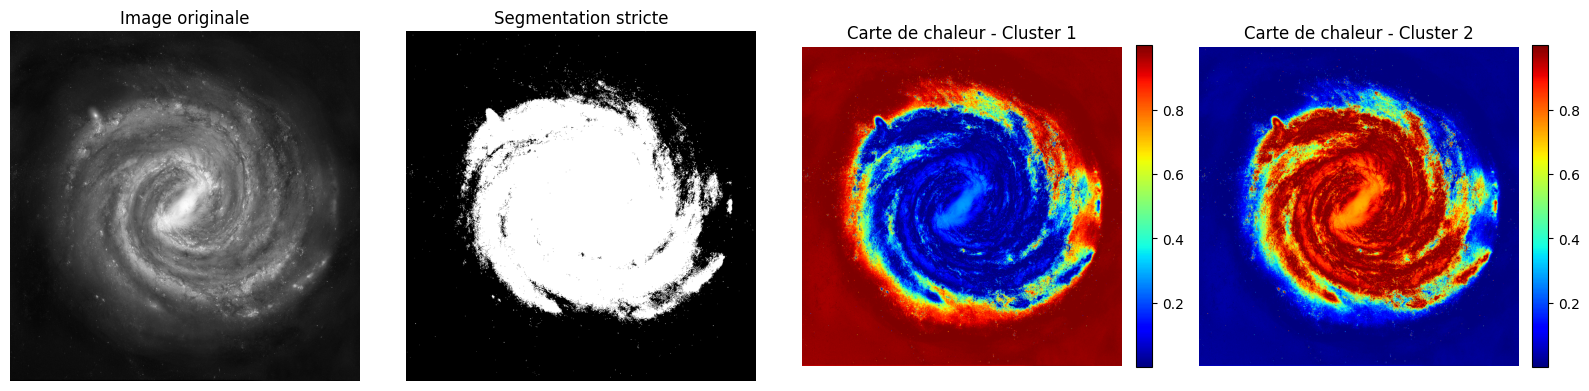

In [ ]:
# Chargement de l'image en niveaux de gris depuis le Drive
image_path_nvg = "/content/drive/MyDrive/DataFuzzy/milky-way-nvg.jpg"
image_nvg = cv2.imread(image_path_nvg, cv2.IMREAD_GRAYSCALE)

if image_nvg is None:
    print(f"Erreur : Impossible de charger l'image {image_path_nvg}")
else:
    # Préparation des données
    data_nvg = image_nvg.flatten().astype(float)

    # Définition des paramètres
    K = 2
    m = 2.0
    epsilon = 0.01

    print("Exécution de l'algorithme FCM en niveaux de gris...")
    # Exécution de l'algorithme
    centroides_nvg, U_nvg = exec_fcm(data_nvg, K, m, epsilon)

    # Récupération de la segmentation
    image_segmentee_nvg, cartes_floues_nvg = segmenter_image(image_nvg, U_nvg)

    # Affichage
    plt.figure(figsize=(16, 5))
    plt.subplot(1, K+2, 1)
    plt.title("Image originale")
    plt.imshow(image_nvg, cmap='gray')
    plt.axis('off')

    plt.subplot(1, K+2, 2)
    plt.title("Segmentation stricte")
    plt.imshow(image_segmentee_nvg, cmap='gray')
    plt.axis('off')

    for i in range(K):
        plt.subplot(1, K+2, i+3)
        plt.title(f"Carte de chaleur - Cluster {i+1}")
        plt.imshow(cartes_floues_nvg[:, :, i], cmap='jet')
        plt.colorbar(fraction=0.046, pad=0.04)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

## Tests sur l'image en couleurs :

Exécution de l'algorithme FCM en couleurs...


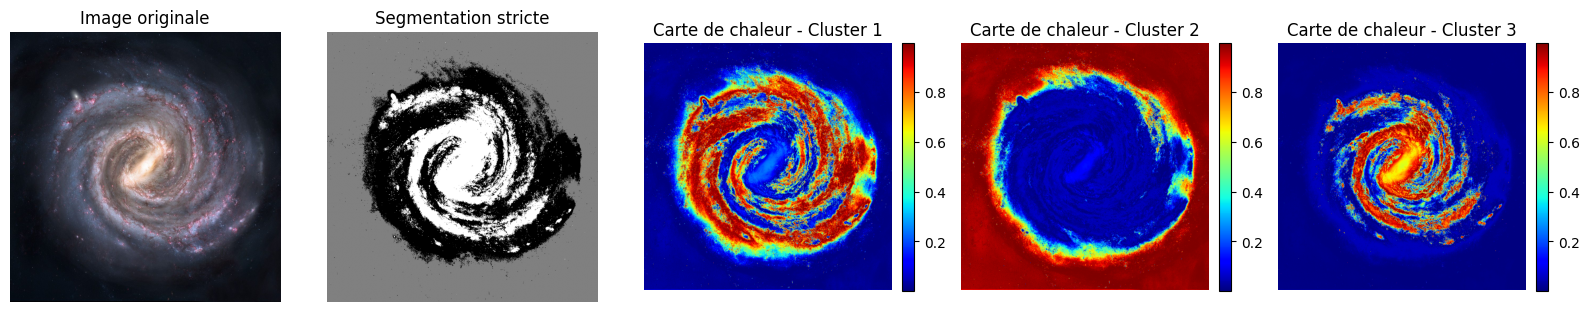

In [ ]:
# Chargement de l'image en couleur depuis le Drive
image_path_color = "/content/drive/MyDrive/DataFuzzy/milky-way.jpg"
image_color = cv2.imread(image_path_color, cv2.IMREAD_COLOR)

if image_color is None:
    print(f"Erreur : Impossible de charger l'image {image_path_color}")
else:
    # Conversion BGR vers RGB
    image_color = cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB)

    # Préparation des données
    data_color = image_color.reshape((-1, 3)).astype(float)

    # Définition des paramètres
    K_color = 3
    m_color = 2.0
    epsilon_color = 0.01

    print("Exécution de l'algorithme FCM en couleurs...")
    # Exécution de l'algorithme
    centroides_color, U_color = exec_fcm(data_color, K_color, m_color, epsilon_color)

    # Récupération de la segmentation
    image_segmentee_color, cartes_floues_color = segmenter_image(image_color, U_color)

    # Affichage
    plt.figure(figsize=(16, 5))
    plt.subplot(1, K_color+2, 1)
    plt.title("Image originale")
    plt.imshow(image_color)
    plt.axis('off')

    plt.subplot(1, K_color+2, 2)
    plt.title("Segmentation stricte")
    plt.imshow(image_segmentee_color, cmap='gray')
    plt.axis('off')

    for i in range(K_color):
        plt.subplot(1, K_color+2, i+3)
        plt.title(f"Carte de chaleur - Cluster {i+1}")
        plt.imshow(cartes_floues_color[:, :, i], cmap='jet')
        plt.colorbar(fraction=0.046, pad=0.04)
        plt.axis('off')

    plt.tight_layout()
    plt.show()